Output()

Output()

Output()

Output()

Output()

Output()

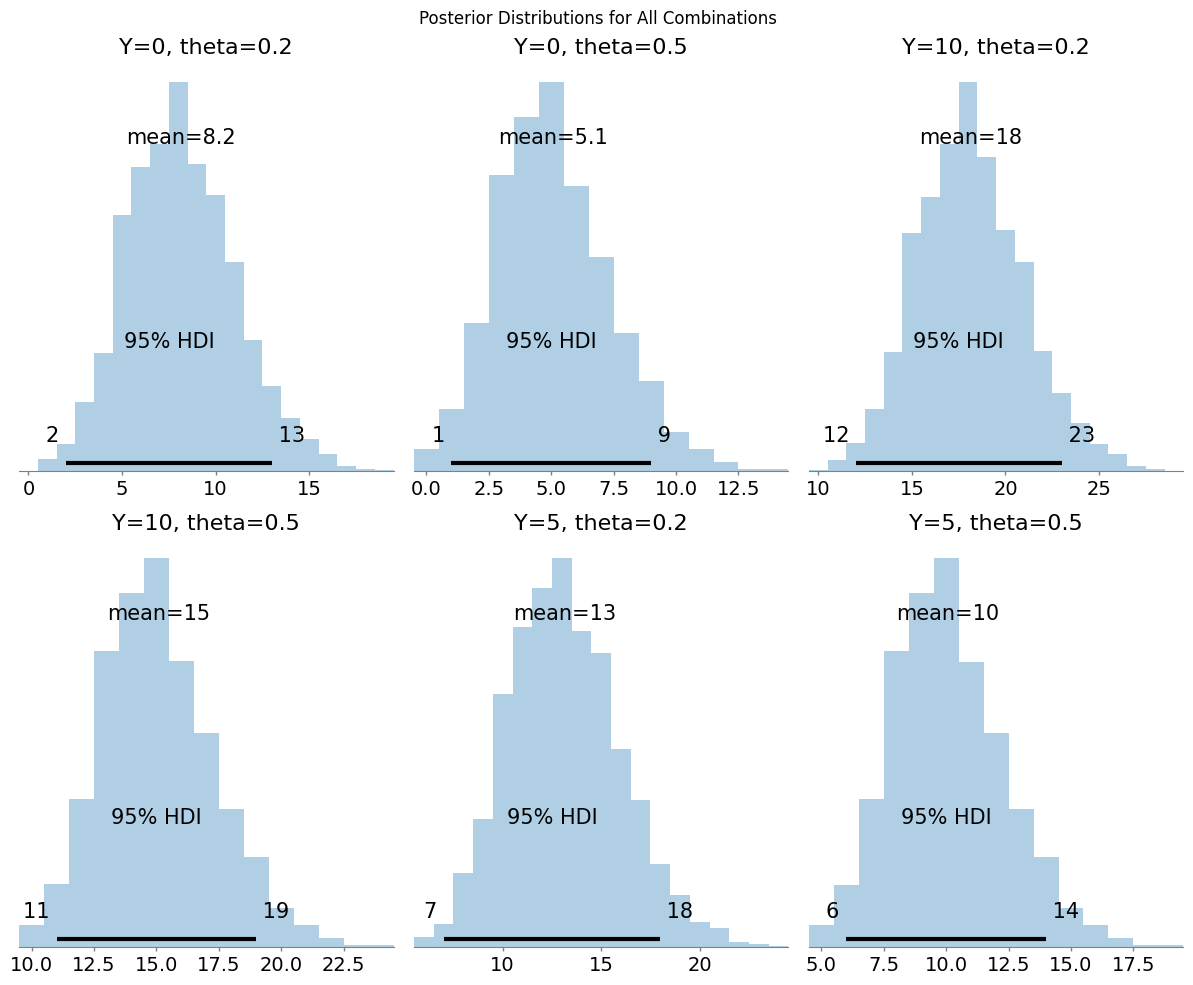

In [ ]:
import pymc as pm
import arviz as az
import numpy as np
import matplotlib.pyplot as plt

Y_values = [0, 5, 10]
theta_values = [0.2, 0.5]

results = {}

for Y in Y_values:
    for theta in theta_values:

        with pm.Model() as model:

            n = pm.Poisson("n", mu=10)

            obs = pm.Binomial(
                "obs",
                n=n,
                p=theta,
                observed=Y
            )

            idata = pm.sample(
                draws=2000,
                tune=1000,
                chains=4,
                random_seed=42,
                initvals={"n": max(10, Y)}
            )

        label = f"Y={Y}, theta={theta}"
        results[label] = idata.posterior["n"].values.flatten()

az.plot_posterior(
    results,
    hdi_prob=0.95,
    figsize=(12, 10))

plt.suptitle("Posterior Distributions for All Combinations")
plt.tight_layout()
plt.show()